# DNS Exfiltration Detection: EDA and Feature Engineering
## From Raw DNS Queries to Discriminative ML Features

This notebook combines exploratory data analysis with the feature engineering pipeline implemented in `src/features.py`. It examines distinguishing statistical, lexical, and structural characteristics between **benign web lookups** (e.g. Tranco 1M) and **malicious DNS exfiltration/tunneling traffic** (e.g., Base32, Hex, CIC-Bell-DNS-EXF-2021), then demonstrates how raw DNS queries become machine-learning features.

### Notebook Objectives:
1. Demonstrate the entropy, structural, lexical, and temporal features used for detection.
2. Compare query characteristics between benign and malicious traffic.
3. Process labeled traffic into a feature matrix ready for ML training.
4. Identify the strongest features associated with the malicious target label.

In [1]:
import os
import sys
import yaml
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Ensure repo root is on sys.path
for p in [".", "..", "../.."]:
    if os.path.exists(os.path.join(p, "configs", "config.yaml")):
        sys.path.insert(0, os.path.abspath(p))
        REPO_ROOT = os.path.abspath(p)
        break

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# Feature engineering functions used in the walkthrough below
from src.features import (
    compute_entropy,
    split_domain_components,
    extract_domain_features,
    calculate_query_frequency,
    process_traffic_dataset,
)

print(f"Repository Root: {REPO_ROOT}")
print("Feature engineering modules loaded successfully.")

Repository Root: /home/hyperghost/github/dns-exfiltration-rm
Feature engineering modules loaded successfully.


In [7]:
# Load configuration
config_path = os.path.join(REPO_ROOT, "configs", "config.yaml")
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

data_path = os.path.join(REPO_ROOT, config["paths"]["features_dataset_csv"])
print(f"Target Feature Dataset: {data_path}")

Target Feature Dataset: /home/hyperghost/github/dns-exfiltration-rm/data/processed/dns_features.csv


In [8]:
# Load processed feature dataset or generate synthetic benchmark if not yet created
if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    print(f"Loaded {len(df)} records from {data_path}")
else:
    print("Processed dataset not found. Generating synthetic benchmark dataset...")
    from src.train import generate_synthetic_dataset
    df = generate_synthetic_dataset(n_samples=2000)
    os.makedirs(os.path.dirname(data_path), exist_ok=True)
    df.to_csv(data_path, index=False)

df.head(6)

Loaded 115 records from /home/hyperghost/github/dns-exfiltration-rm/data/processed/dns_features.csv


,domain_len,subdomain_len,num_labels,max_label_len,min_label_len,avg_label_len,entropy,subdomain_entropy,max_label_entropy,digit_ratio,...,vowel_consonant_ratio,special_ratio,subdomain_digit_ratio,subdomain_hex_ratio,unique_char_ratio,max_consecutive_consonants,domain,label,attack_type,queries_per_minute
0,9,0,2,5,3,4.00,2.9477,0.0000,2.3219,0.0000,...,0.1429,0.0000,0.0,0.0,0.8889,5,fbcdn.net,0,benign,1.0
1,6,0,2,3,2,2.50,1.9183,0.0000,1.0000,0.0000,...,0.6667,0.0000,0.0,0.0,0.6667,2,goo.gl,0,benign,1.0
2,18,5,3,8,3,5.33,3.4613,2.3219,2.5000,0.0556,...,0.4000,0.0556,0.2,0.6,0.6667,3,cdn-4.linkedin.com,0,benign,1.0
3,17,5,3,7,3,5.00,3.6169,2.3219,2.3219,0.0588,...,0.4444,0.0588,0.2,0.6,0.7647,3,cdn-9.reuters.com,0,benign,1.0
4,10,0,2,7,2,4.50,2.9219,0.0000,2.5216,0.0000,...,0.2857,0.0000,0.0,0.0,0.8000,2,discord.gg,0,benign,1.0
5,11,0,2,7,3,5.00,3.2776,0.0000,2.8074,0.0000,...,0.4286,0.0000,0.0,0.0,0.9091,2,shopify.com,0,benign,1.0


=== Class Distribution ===
label
0    60
1    55
Name: count, dtype: int64

Proportions:
label
0    0.5217
1    0.4783
Name: proportion, dtype: float64


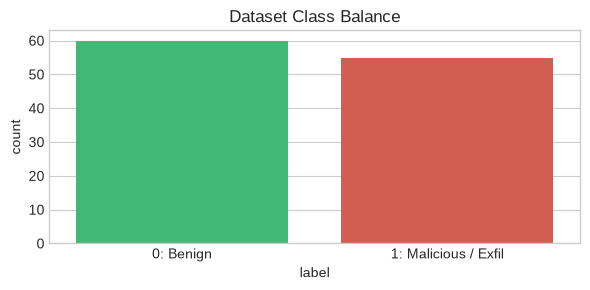

In [4]:
# Class distribution
print("=== Class Distribution ===")
class_counts = df["label"].value_counts()
print(class_counts)
print("\nProportions:")
print(df["label"].value_counts(normalize=True).round(4))

fig, ax = plt.subplots(figsize=(6, 3))
sns.countplot(data=df, x="label", hue="label", legend=False, palette=["#2ecc71", "#e74c3c"], ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0: Benign", "1: Malicious / Exfil"])
ax.set_title("Dataset Class Balance")
plt.tight_layout()
plt.show()

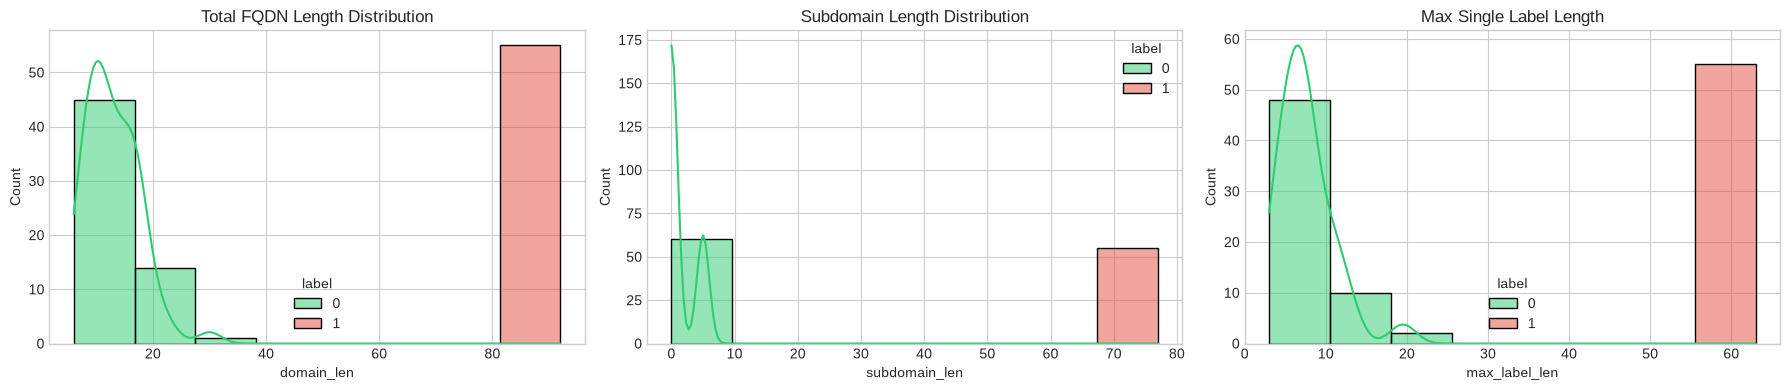

In [5]:
# Visualizing Query Lengths: domain_len, subdomain_len, max_label_len
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(data=df, x="domain_len", hue="label", kde=True, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Total FQDN Length Distribution")

sns.histplot(data=df, x="subdomain_len", hue="label", kde=True, ax=axes[1], palette=["#2ecc71", "#e74c3c"])
axes[1].set_title("Subdomain Length Distribution")

sns.histplot(data=df, x="max_label_len", hue="label", kde=True, ax=axes[2], palette=["#2ecc71", "#e74c3c"])
axes[2].set_title("Max Single Label Length")

plt.tight_layout()
plt.show()

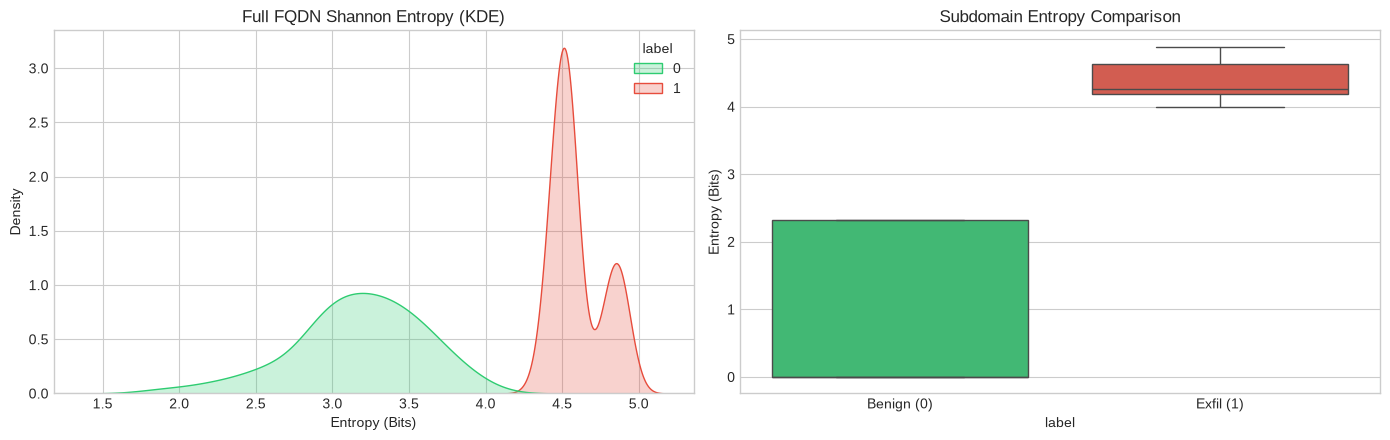

In [6]:
# Visualizing Information Theory: Shannon Entropy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.kdeplot(data=df, x="entropy", hue="label", fill=True, common_norm=False, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_title("Full FQDN Shannon Entropy (KDE)")
axes[0].set_xlabel("Entropy (Bits)")

sns.boxplot(data=df, x="label", y="subdomain_entropy", hue="label", legend=False, palette=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Benign (0)", "Exfil (1)"])
axes[1].set_title("Subdomain Entropy Comparison")
axes[1].set_ylabel("Entropy (Bits)")

plt.tight_layout()
plt.show()

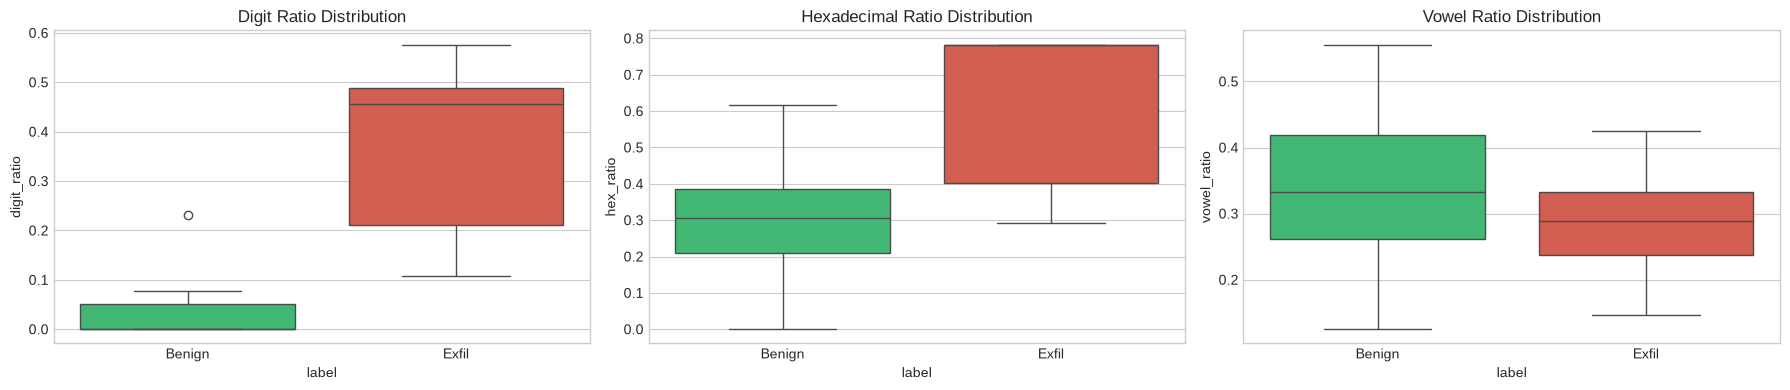

In [7]:
# Character Distributions: Digit Ratio, Hex Ratio, and Vowel/Consonant Ratio
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.boxplot(data=df, x="label", y="digit_ratio", hue="label", legend=False, palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Benign", "Exfil"])
axes[0].set_title("Digit Ratio Distribution")

sns.boxplot(data=df, x="label", y="hex_ratio", hue="label", legend=False, palette=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Benign", "Exfil"])
axes[1].set_title("Hexadecimal Ratio Distribution")

sns.boxplot(data=df, x="label", y="vowel_ratio", hue="label", legend=False, palette=["#2ecc71", "#e74c3c"], ax=axes[2])
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Benign", "Exfil"])
axes[2].set_title("Vowel Ratio Distribution")

plt.tight_layout()
plt.show()

Top Correlations with Label (1 = Exfiltration):
subdomain_len                 0.999108
domain_len                    0.996434
max_label_len                 0.996085
avg_label_len                 0.982663
num_labels                    0.973710
subdomain_entropy             0.925925
entropy                       0.913467
digit_ratio                   0.878597
max_label_entropy             0.865921
subdomain_digit_ratio         0.842653
subdomain_hex_ratio           0.759946
hex_ratio                     0.743845
max_consecutive_consonants    0.354835
min_label_len                 0.311376
consonant_ratio               0.250923
special_ratio                -0.193125
vowel_ratio                  -0.250923
vowel_consonant_ratio        -0.288486
alpha_ratio                  -0.811708
unique_char_ratio            -0.936099
queries_per_minute                 NaN


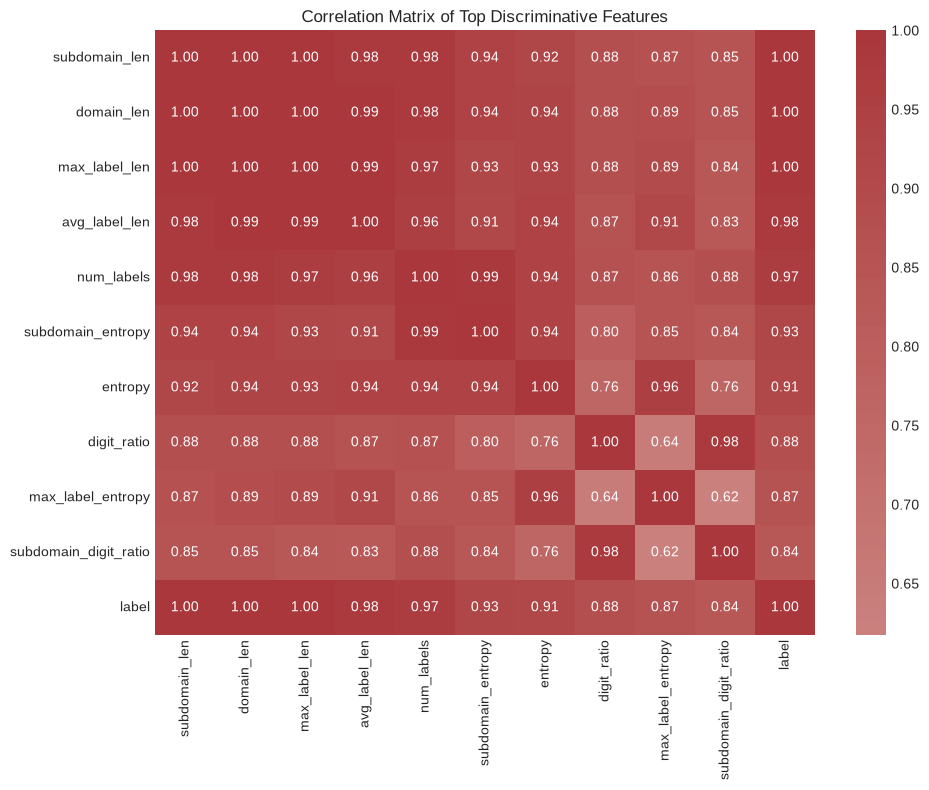

In [8]:
# Feature Correlation Matrix
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ["label"]]
corr_series = df[numeric_cols].apply(lambda x: x.corr(df["label"])).sort_values(ascending=False)

print("Top Correlations with Label (1 = Exfiltration):")
print(corr_series.to_string())

plt.figure(figsize=(10, 8))
top_corr_features = list(corr_series.abs().head(10).index) + ["label"]
sns.heatmap(df[top_corr_features].corr(), annot=True, cmap="vlag", fmt=".2f", center=0)
plt.title("Correlation Matrix of Top Discriminative Features")
plt.tight_layout()
plt.show()

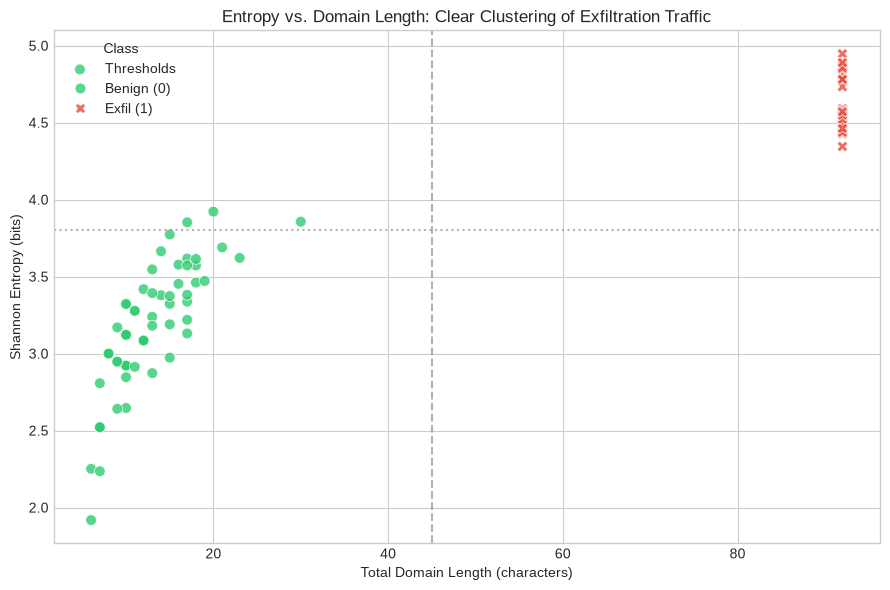

In [9]:
# 2D Scatter: Shannon Entropy vs Domain Length Decision Boundary
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="domain_len",
    y="entropy",
    hue="label",
    style="label",
    alpha=0.8,
    palette=["#2ecc71", "#e74c3c"],
    s=60
)
plt.axvline(x=45, color="grey", linestyle="--", alpha=0.6, label="RFC / Typical Benign Threshold")
plt.axhline(y=3.8, color="grey", linestyle=":", alpha=0.6, label="Entropy Threshold (~3.8)")
plt.title("Entropy vs. Domain Length: Clear Clustering of Exfiltration Traffic")
plt.xlabel("Total Domain Length (characters)")
plt.ylabel("Shannon Entropy (bits)")
plt.legend(title="Class", labels=["Thresholds", "Benign (0)", "Exfil (1)"])
plt.tight_layout()
plt.show()

### EDA Findings Summary:
1. **Query Lengths**: Benign domain names concentrate in 10-25 characters. Exfiltration queries consistently exceed 45+ characters to maximize throughput per packet.
2. **Shannon Entropy**: Benign names exhibit natural language entropy (~2.0 - 3.2 bits). Encoded Base32/Hex payloads exhibit significantly higher entropy (>3.8 bits).
3. **Character Distributions**: Encoded tunneling payloads feature high hexadecimal density and low vowel ratios, which heavily contrasts with natural linguistic domains.
4. **Conclusion**: Lexical and entropy features provide strong separation for linear and tree-based machine learning classifiers.

## Feature Engineering Walkthrough

The sections below demonstrate how the raw DNS query signal is transformed into the features analyzed above.

### 1. Information-Theoretic Metrics: Shannon Entropy

Shannon entropy quantifies the uncertainty or randomness of characters in a string:

$$H(X) = - \sum_{i=1}^n P(x_i) \log_2 P(x_i)$$

Natural domain names have repetitive linguistic patterns and lower entropy, while Base32 and Hex encoded DNS tunnel payloads exhibit higher entropy.

In [2]:
# Comparing entropy across benign, Base32, and Hex queries
sample_queries = {
    "Benign - Standard": "google.com",
    "Benign - Subdomain": "cdn.assets.cloudflare.net",
    "Exfil - Base32": "sq0001.krsxg5bamnxw4ztjmrsw45djmfwcazdb.tunnel.example.com",
    "Exfil - Hex": "sq0001.5465737420636f6e666964656e7469616c.tunnel.example.com",
}

for description, query in sample_queries.items():
    entropy = compute_entropy(query)
    parts = split_domain_components(query)
    subdomain_entropy = compute_entropy(parts["subdomain"]) if parts["subdomain"] else 0.0
    print(f"{description:20} | FQDN: {query[:45]:45}... | Total H: {entropy:.4f} | Subdomain H: {subdomain_entropy:.4f}")

Benign - Standard    | FQDN: google.com                                   ... | Total H: 2.6464 | Subdomain H: 0.0000
Benign - Subdomain   | FQDN: cdn.assets.cloudflare.net                    ... | Total H: 3.5933 | Subdomain H: 2.8464
Exfil - Base32       | FQDN: sq0001.krsxg5bamnxw4ztjmrsw45djmfwcazdb.tunne... | Total H: 4.6012 | Subdomain H: 4.5285
Exfil - Hex          | FQDN: sq0001.5465737420636f6e666964656e7469616c.tun... | Total H: 4.1198 | Subdomain H: 3.7439


### 2. Lexical & Structural Metrics: Label Lengths and Components

According to RFC 1035, labels must not exceed 63 characters and FQDNs must not exceed 253 characters. Attackers maximize label capacity to carry encoded payloads.

In [3]:
# Extracting component and length features
engineered_demo_features = []
for description, query in sample_queries.items():
    features = extract_domain_features(query)
    features["description"] = description
    engineered_demo_features.append(features)

df_demo = pd.DataFrame(engineered_demo_features)
feature_columns = ["description", "domain_len", "subdomain_len", "num_labels", "max_label_len", "avg_label_len", "entropy"]
df_demo[feature_columns]

,description,domain_len,subdomain_len,num_labels,max_label_len,avg_label_len,entropy
0,Benign - Standard,10,0,2,6,4.5,2.6464
1,Benign - Subdomain,25,10,4,10,5.5,3.5933
2,Exfil - Base32,58,46,5,32,10.8,4.6012
3,Exfil - Hex,60,48,5,34,11.2,4.1198


### 3. Linguistic Ratios: Vowels, Digits, and Consonants

Normal human-readable domains have regular vowel-to-consonant patterns. Encoded payloads tend to have higher digit or hexadecimal ratios and longer consonant runs.

In [4]:
# Inspecting ratio metrics
ratio_columns = ["description", "digit_ratio", "hex_ratio", "vowel_ratio", "consonant_ratio", "max_consecutive_consonants"]
df_demo[ratio_columns]

,description,digit_ratio,hex_ratio,vowel_ratio,consonant_ratio,max_consecutive_consonants
0,Benign - Standard,0.0000,0.2000,0.4444,0.5556,2
1,Benign - Subdomain,0.0000,0.4000,0.3182,0.6818,3
2,Exfil - Base32,0.1379,0.3621,0.1739,0.8261,7
3,Exfil - Hex,0.5667,0.7167,0.3636,0.6364,3


### 4. Temporal Frequency Metrics: Burst vs. Low-and-Slow

Burst attacks send many queries in seconds, while low-and-slow attacks space queries out to evade volume-based alarms.

In [5]:
# Demonstrating rolling query frequency computation
time_records = pd.DataFrame({
    "qname": ["tunnel.exfil.org"] * 5 + ["google.com"] * 2,
    "timestamp": [1710000000.0, 1710000001.0, 1710000002.0, 1710000002.5, 1710000003.0, 1710000000.0, 1710000030.0],
})

frequency_result = calculate_query_frequency(time_records, window="10s", rate_unit="second")
frequency_result

,qname,timestamp,queries_per_second
0,google.com,1.710000e+09,0.1
1,google.com,1.710000e+09,0.1
2,tunnel.exfil.org,1.710000e+09,0.1
3,tunnel.exfil.org,1.710000e+09,0.2
4,tunnel.exfil.org,1.710000e+09,0.3
5,tunnel.exfil.org,1.710000e+09,0.4
6,tunnel.exfil.org,1.710000e+09,0.5


### 5. Full Pipeline: Processing Raw Traffic into an ML Feature Dataset

In [9]:
# Process existing labeled traffic dataset or synthesize a session
raw_traffic_path = os.path.join(REPO_ROOT, config["paths"].get("labeled_traffic_csv", "data/processed/labeled_traffic.csv"))
output_features_path = os.path.join(REPO_ROOT, config["paths"].get("features_dataset_csv", "data/processed/dns_features.csv"))

if os.path.exists(raw_traffic_path):
    print(f"Loading raw traffic from {raw_traffic_path}...")
    df_raw = pd.read_csv(raw_traffic_path)
else:
    print("Synthesizing raw traffic session...")
    from src.capture_traffic import generate_synthesized_traffic
    records, _ = generate_synthesized_traffic(benign_count=200, burst_count=120, low_slow_count=40)
    df_raw = pd.DataFrame(records)

# Execute feature extraction pipeline
df_features = process_traffic_dataset(df_raw, window="60s")
os.makedirs(os.path.dirname(output_features_path), exist_ok=True)
df_features.to_csv(output_features_path, index=False)

print(f"Successfully processed {len(df_features)} records into feature matrix.")
print(f"Saved feature dataset to: {output_features_path}")
df_features.head()

Loading raw traffic from /home/hyperghost/github/dns-exfiltration-rm/data/processed/labeled_traffic.csv...
Successfully processed 115 records into feature matrix.
Saved feature dataset to: /home/hyperghost/github/dns-exfiltration-rm/data/processed/dns_features.csv


,domain_len,subdomain_len,num_labels,max_label_len,min_label_len,avg_label_len,entropy,subdomain_entropy,max_label_entropy,digit_ratio,...,vowel_consonant_ratio,special_ratio,subdomain_digit_ratio,subdomain_hex_ratio,unique_char_ratio,max_consecutive_consonants,domain,label,attack_type,queries_per_minute
0,9,0,2,5,3,4.00,2.9477,0.0000,2.3219,0.0000,...,0.1429,0.0000,0.0,0.0,0.8889,5,fbcdn.net,0,benign,1.0
1,6,0,2,3,2,2.50,1.9183,0.0000,1.0000,0.0000,...,0.6667,0.0000,0.0,0.0,0.6667,2,goo.gl,0,benign,1.0
2,18,5,3,8,3,5.33,3.4613,2.3219,2.5000,0.0556,...,0.4000,0.0556,0.2,0.6,0.6667,3,cdn-4.linkedin.com,0,benign,1.0
3,17,5,3,7,3,5.00,3.6169,2.3219,2.3219,0.0588,...,0.4444,0.0588,0.2,0.6,0.7647,3,cdn-9.reuters.com,0,benign,1.0
4,10,0,2,7,2,4.50,2.9219,0.0000,2.5216,0.0000,...,0.2857,0.0000,0.0,0.0,0.8000,2,discord.gg,0,benign,1.0


In [10]:
# Feature summary and correlation with target
numeric_features = [column for column in df_features.select_dtypes(include=[np.number]).columns if column != "label"]
print(f"Total numeric features generated: {len(numeric_features)}")
print(numeric_features)

if "label" in df_features.columns:
    feature_correlations = df_features[numeric_features].apply(
        lambda values: values.corr(df_features["label"])
    ).sort_values(ascending=False)
    print("\nFeature correlation with malicious label:")
    print(feature_correlations.round(4).to_string())

Total numeric features generated: 21
['domain_len', 'subdomain_len', 'num_labels', 'max_label_len', 'min_label_len', 'avg_label_len', 'entropy', 'subdomain_entropy', 'max_label_entropy', 'digit_ratio', 'alpha_ratio', 'hex_ratio', 'vowel_ratio', 'consonant_ratio', 'vowel_consonant_ratio', 'special_ratio', 'subdomain_digit_ratio', 'subdomain_hex_ratio', 'unique_char_ratio', 'max_consecutive_consonants', 'queries_per_minute']

Feature correlation with malicious label:
subdomain_len                 0.9991
domain_len                    0.9964
max_label_len                 0.9961
avg_label_len                 0.9827
num_labels                    0.9737
subdomain_entropy             0.9259
entropy                       0.9135
digit_ratio                   0.8786
max_label_entropy             0.8659
subdomain_digit_ratio         0.8427
subdomain_hex_ratio           0.7599
hex_ratio                     0.7438
max_consecutive_consonants    0.3548
min_label_len                 0.3114
consonant_ra